# Title

Some description

![montage](img/montage.png)

# Read data

In [1]:
import os

import matplotlib.pyplot as plt
import mne
import mne_bids
import mne_nirs
import numpy as np
import pandas as pd

import seaborn as sns
import statsmodels.formula.api as smf
import matplotlib as mpl

from itertools import compress
from nilearn.plotting import plot_design_matrix
from statsmodels.stats.outliers_influence import variance_inflation_factor

# BIDS dataset and task
task = "lettersearch"
bids_root = "data/lettersearch_BIDS"
datatype = 'nirs'
bids_folder = mne_bids.BIDSPath(root=bids_root, datatype=datatype)
nirs_files = bids_folder.match()

# Prepare folder for processed data
glm_folder = "data/glm_data"
if not os.path.isdir(glm_folder):
    os.mkdir(glm_folder)

# Parameters used
sci_limit = 0.8
excluded_participants = []

# For visualization
subjects_dir = str(mne.datasets.sample.data_path()) + '/subjects'
mne.datasets.fetch_fsaverage(subjects_dir=subjects_dir)
mne.set_config('MNE_NIRS_FOLD_PATH', 'data/fOLD-public/Supplementary')


0 files missing from root.txt in /Users/alexander.kvist/mne_data/MNE-sample-data/subjects
0 files missing from bem.txt in /Users/alexander.kvist/mne_data/MNE-sample-data/subjects/fsaverage


# Set up design matrix

ISI is based on ....


Loading /Users/alexander.kvist/project_local/Perceptual-fnirs/data/lettersearch_BIDS/sub-P1/nirs/sub-P1_task-lettersearch_nirs.snirf
Found jitter of 0.000000% in sample times.
Reading events from data/lettersearch_BIDS/sub-P1/nirs/sub-P1_task-lettersearch_events.tsv.
Reading channel info from data/lettersearch_BIDS/sub-P1/nirs/sub-P1_task-lettersearch_channels.tsv.
Not fully anonymizing info - keeping hand, his_id, sex of subject_info
Reading 0 ... 5014  =      0.000 ...   985.793 secs...
Reading 0 ... 5014  =      0.000 ...   985.793 secs...
          ACCEL_X_1  ACCEL_X_2  ACCEL_Y_2  ACCEL_Z_2  GYRO_X_2  GYRO_Y_2  \
times                                                                      
0.000000  -0.025000  -0.004000   1.060000  -9.197000 -0.015251  0.000000   
0.196608  -0.058828  -0.078241   1.150174  -9.190414  0.052679 -0.045756   
0.393216   0.028000  -0.210378   1.011860  -9.194551 -0.007595 -0.008514   
0.589824  -0.028556  -0.117207   1.053747  -9.219788 -0.047704 -0.00099

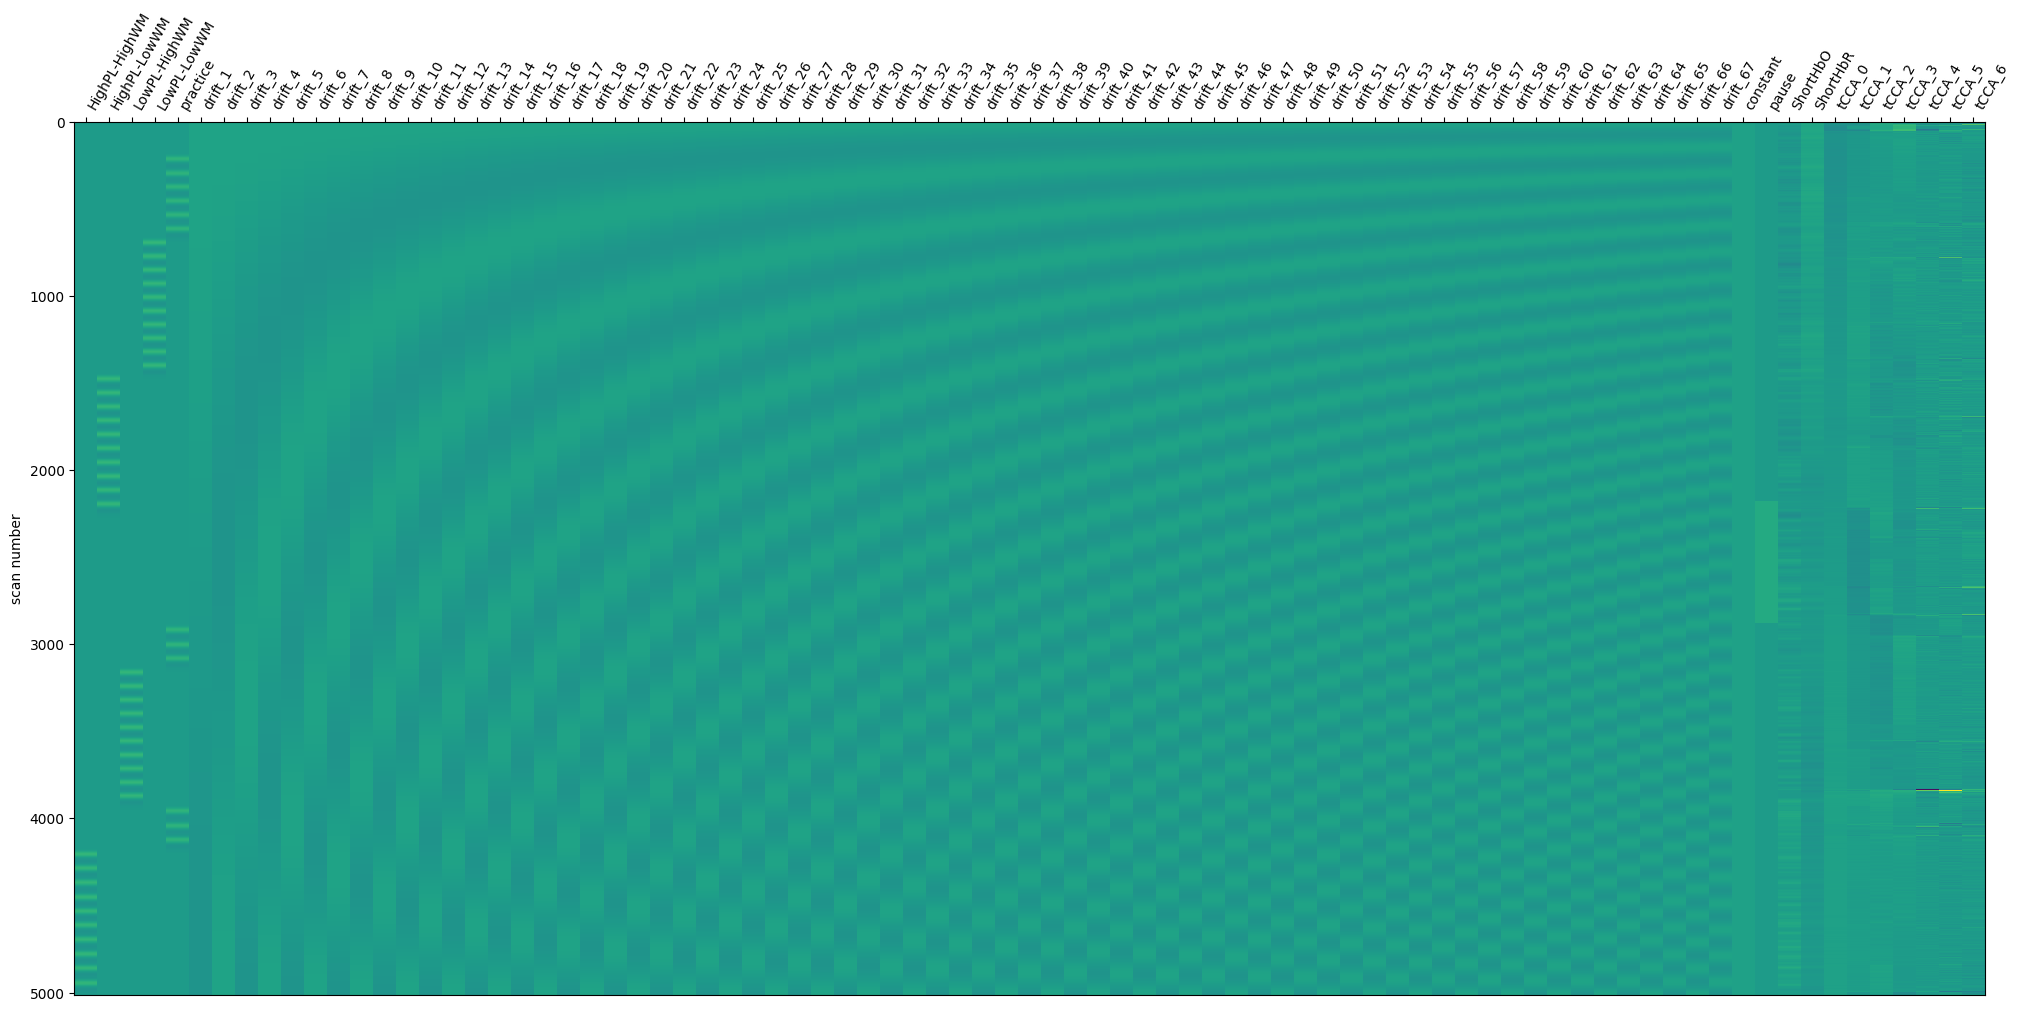

In [2]:
# Get all subjects in a sorted list
all_subjects = [file.subject for file in nirs_files]
all_subjects = sorted(list(set(all_subjects)))

# Get hemo data for one subject to illustrate design matrix
subject = all_subjects[0]
bids_path = mne_bids.BIDSPath(subject=subject, task=task,
                            suffix=datatype, datatype=datatype,
                            root=bids_root)

raw_intensity = mne_bids.read_raw_bids(bids_path=bids_path)

# Split into long/short
long_chs = mne_nirs.channels.get_long_channels(raw_intensity)
short_chs = mne_nirs.channels.get_short_channels(raw_intensity)

# Convert to hemoglobin
raw_od_long = mne.preprocessing.nirs.optical_density(long_chs)
raw_od_short = mne.preprocessing.nirs.optical_density(short_chs)
raw_haemo_long = mne.preprocessing.nirs.beer_lambert_law(raw_od_long, ppf=0.1)
raw_haemo_short = mne.preprocessing.nirs.beer_lambert_law(raw_od_short, ppf=0.1)

# Create a design matrix
design_matrix = mne_nirs.experimental_design.make_first_level_design_matrix(raw_haemo_long,
                                                                            drift_model="cosine",
                                                                            stim_dur=5,
                                                                            hrf_model="glover",
                                                                            high_pass=0.034)

# Add a boxcar regressor for the long pause
# First get gaps between blocks
onsets = raw_haemo_long.annotations.onset
durations = raw_haemo_long.annotations.duration
ends = onsets + durations
gaps = onsets[1:] - ends[:-1]

# The longest gap is guaranteed to be the pause
pause_idx = np.argmax(gaps)
pause_start_sec = ends[pause_idx]
pause_stop_sec = onsets[pause_idx+1]

# Create a pause regressor (can be confirmed visually)
pause_regressor = np.zeros(len(raw_haemo_long.times))
start_idx = np.searchsorted(raw_haemo_long.times, pause_start_sec)
stop_idx = np.searchsorted(raw_haemo_long.times, pause_stop_sec)
pause_regressor[start_idx:stop_idx] = 1.0
design_matrix["pause"] = pause_regressor

# Add short separation regressors
design_matrix["ShortHbO"] = np.mean(
    raw_haemo_short.copy().pick(picks="hbo").get_data(), axis=0
)
design_matrix["ShortHbR"] = np.mean(
    raw_haemo_short.copy().pick(picks="hbr").get_data(), axis=0
)

# Add acceleration regressors
aux_df = mne_nirs.io.snirf.read_snirf_aux_data(raw_intensity.filenames[0], raw_intensity)
print(aux_df.head())

aux_all = aux_df.to_numpy()
nirs_data = raw_haemo_long.copy().pick(picks="hbo").get_data().T

reg, tcca_info = mne_nirs.experimental_design.rtcca(
    nirs_data,
    aux_all,
    tau=1,
    n_emb=3,
    ct=0.3,
    pca_fnirs = False,
    pca_aux = False,
    shrink=True
)

print(reg.shape)
reg_names = [f"tCCA_{i}" for i in range(reg.shape[1])]
for i, name in zip(range(reg.shape[1]), reg_names):
    design_matrix[name] = reg[:, i]

# Plot final matrix
fig = plot_design_matrix(design_matrix)
plt.show()

In [3]:
# Go through data for each subject
cha_frames = []
for subject in all_subjects:
    
    # Get SNIRF file for this subject
    bids_path = mne_bids.BIDSPath(subject=subject, task=task,
                            suffix=datatype, datatype=datatype,
                            root=bids_root)
    
    print(f"Processing {bids_path}..")
    if not os.path.exists(bids_path):
        print(f"No SNIRF file, skip: {bids_path}")
        continue

    # Raw data
    raw_intensity = mne_bids.read_raw_bids(bids_path=bids_path)

    # Split into long/short
    long_chs = mne_nirs.channels.get_long_channels(raw_intensity)
    short_chs = mne_nirs.channels.get_short_channels(raw_intensity)

    # Convert to OD
    raw_od_long = mne.preprocessing.nirs.optical_density(long_chs)
    raw_od_short = mne.preprocessing.nirs.optical_density(short_chs)

    # Channel quality
    sci = mne.preprocessing.nirs.scalp_coupling_index(raw_od_long)
    bad_channels = list(compress(raw_od_long.ch_names, sci < sci_limit))
    
    # Get bad channel names as e.g. S1_D1 instead of S1_D1 760 and S1_D1 850
    bad_channels = np.unique([channel.replace(" 760", "").replace(" 850", "") for channel in np.unique(bad_channels)]).tolist()
    print(f"Bad channels with SCI < {sci_limit}:")
    print(bad_channels)

    # Use the MBLL to convert into hemoglobin changes
    raw_haemo_long = mne.preprocessing.nirs.beer_lambert_law(raw_od_long, ppf=0.1)
    raw_haemo_short = mne.preprocessing.nirs.beer_lambert_law(raw_od_short, ppf=0.1)

    # Where to store results from the GLM analysis
    glm_fname = f"{glm_folder}/{subject}_glm.h5"

    # Create a design matrix
    design_matrix = mne_nirs.experimental_design.make_first_level_design_matrix(raw_haemo_long,
                                                                                stim_dur=5,
                                                                                drift_model="cosine",
                                                                                hrf_model="glover",
                                                                                high_pass=0.034)
    design_matrix["ShortHbO"] = np.mean(
        raw_haemo_short.copy().pick(picks="hbo").get_data(), axis=0
    )
    design_matrix["ShortHbR"] = np.mean(
        raw_haemo_short.copy().pick(picks="hbr").get_data(), axis=0
    )

    # Add a boxcar regressor for the long pause
    # First get gaps between blocks
    onsets = raw_haemo_long.annotations.onset
    durations = raw_haemo_long.annotations.duration
    ends = onsets + durations
    gaps = onsets[1:] - ends[:-1]
    
    # The longest gap is guaranteed to be the pause
    pause_idx = np.argmax(gaps)
    pause_start_sec = ends[pause_idx]
    pause_stop_sec = onsets[pause_idx+1]
    
    # Create a pause regressor (can be confirmed visually)
    pause_regressor = np.zeros(len(raw_haemo_long.times))
    start_idx = np.searchsorted(raw_haemo_long.times, pause_start_sec)
    stop_idx = np.searchsorted(raw_haemo_long.times, pause_stop_sec)
    pause_regressor[start_idx:stop_idx] = 1.0
    design_matrix["pause"] = pause_regressor

    # Add acceleration regressors via TCCA
    aux_df = mne_nirs.io.snirf.read_snirf_aux_data(raw_intensity.filenames[0], raw_intensity)
    aux_all = aux_df.to_numpy()
    nirs_data = raw_haemo_long.copy().pick(picks="hbo").get_data().T
    reg, tcca_info = mne_nirs.experimental_design.rtcca(
        nirs_data,
        aux_all,
        tau=1,
        n_emb=3,
        ct=0.3,
        pca_fnirs = False,
        pca_aux = False,
        shrink=True
    )
    reg_names = [f"tCCA_{i}" for i in range(reg.shape[1])]
    for i, name in zip(range(reg.shape[1]), reg_names):
        design_matrix[name] = reg[:, i]

    # Save per-subject VIF
    vif_vals = {design_matrix.columns[i]: variance_inflation_factor(design_matrix.values, i)
                for i in range(design_matrix.shape[1])}
    pd.Series(vif_vals).to_csv(f"{glm_folder}/{subject}_vif.csv")

    # Run GLM and save
    glm_est = mne_nirs.statistics.run_glm(raw_haemo_long, design_matrix, noise_model="auto")
    glm_est.save(glm_fname, overwrite=True)

    # If we want to visualize subject-level GLM
    #glm_est.plot_topo(conditions=['HighPL-HighWM', 'HighPL-LowWM', 'LowPL-HighWM', 'LowPL-LowWM'])
    #plt.show()

    # Append results per channel to larger dataframe for later export
    cha = glm_est.to_dataframe()

    # Add 'channel_ok' column as True for good channels, False for bad channels
    cha['channel_ok'] = cha['ch_name'].apply(lambda x: x.split(' ')[0] not in bad_channels)

    # Append to final dataframes
    cha['subject'] = subject
    cha_frames.append(cha)

cha_data = pd.concat(cha_frames, ignore_index=True)
cha_data.to_csv("data/cha_data.csv")

print('done')

# Also save a raw object for later plotting purposes
raw_haemo_long.save("data/raw.fif", overwrite=True)

Processing data/lettersearch_BIDS/sub-P1/nirs/sub-P1_task-lettersearch_nirs.snirf..
Loading /Users/alexander.kvist/project_local/Perceptual-fnirs/data/lettersearch_BIDS/sub-P1/nirs/sub-P1_task-lettersearch_nirs.snirf
Found jitter of 0.000000% in sample times.
Reading events from data/lettersearch_BIDS/sub-P1/nirs/sub-P1_task-lettersearch_events.tsv.
Reading channel info from data/lettersearch_BIDS/sub-P1/nirs/sub-P1_task-lettersearch_channels.tsv.
Not fully anonymizing info - keeping hand, his_id, sex of subject_info
Reading 0 ... 5014  =      0.000 ...   985.793 secs...
Reading 0 ... 5014  =      0.000 ...   985.793 secs...
Bad channels with SCI < 0.8:
[]
Processing data/lettersearch_BIDS/sub-P10/nirs/sub-P10_task-lettersearch_nirs.snirf..
Loading /Users/alexander.kvist/project_local/Perceptual-fnirs/data/lettersearch_BIDS/sub-P10/nirs/sub-P10_task-lettersearch_nirs.snirf
Found jitter of 0.000000% in sample times.
Reading events from data/lettersearch_BIDS/sub-P10/nirs/sub-P10_task-le

[PosixPath('/Users/alexander.kvist/project_local/Perceptual-fnirs/data/raw.fif')]

In [4]:
import glob

# Load per-subject VIFs saved during the main processing loop and report the mean.
# VIF < 5 for task regressors indicates acceptable orthogonality to other regressors.
# High VIF for nuisance regressors (drift, tCCA) is acceptable — we only need them
# to absorb noise, not to be estimated precisely.
# VIF limits in neuroimaging GLM regressors:
# O'Brien 2007 https://doi.org/10.1007/s11135-006-9018-6
# Mumford 2015 https://doi.org/10.1371/journal.pone.0126255

vif_files = sorted(glob.glob(f"{glm_folder}/*_vif.csv"))
vif_rows = {
    f.split('/')[-1].replace('_vif.csv', ''): pd.read_csv(f, index_col=0, header=None).squeeze()
    for f in vif_files
}
vif_df = pd.DataFrame(vif_rows).T

print(f"Mean VIF across {len(vif_files)} subjects:\n")
print(vif_df.mean().to_string())


Mean VIF across 16 subjects:

0
HighPL-HighWM      1.282194
HighPL-LowWM       1.334125
LowPL-HighWM       1.291685
LowPL-LowWM        1.285103
ShortHbO          26.712611
ShortHbR          90.367854
constant           9.509544
drift_1          115.465925
drift_10           3.817602
drift_11           1.964498
drift_12           2.445926
drift_13           1.760413
drift_14           1.539814
drift_15           1.687043
drift_16           1.709012
drift_17           1.723723
drift_18           1.808739
drift_19           1.737415
drift_2           27.369068
drift_20           1.779732
drift_21           1.771329
drift_22           1.692568
drift_23           1.546485
drift_24           1.420667
drift_25           1.424190
drift_26           1.339053
drift_27           1.258918
drift_28           1.199575
drift_29           1.261320
drift_3           15.180084
drift_30           1.250441
drift_31           1.228140
drift_32           1.257451
drift_33           1.260630
drift_34        

# Group level analysis - channel-level

In [5]:
from statsmodels.stats.multitest import multipletests

cha_data = pd.read_csv("data/cha_data.csv", index_col=0)
raw_haemo_long = mne.io.read_raw_fif("data/raw.fif")

# Get data from the channel level frame - exclude channels flagged as bad during preprocessing
ch_summary_hbo = cha_data.query(
    "Condition in ['HighPL-HighWM', 'HighPL-LowWM', 'LowPL-HighWM', 'LowPL-LowWM'] and channel_ok == True"
)
ch_summary_hbo["theta"] = [t * 1.e6 for t in ch_summary_hbo["theta"]]
ch_summary_hbo = ch_summary_hbo.query("Chroma in ['hbo']")

# Run group level model and convert to dataframe
ch_model_hbo = smf.mixedlm("theta ~ -1 + ch_name:Chroma:Condition",
                    ch_summary_hbo, groups=ch_summary_hbo["subject"]).fit()
ch_model_df_hbo = mne_nirs.statistics.statsmodels_to_results(ch_model_hbo, order=raw_haemo_long.copy().pick("hbo").ch_names)

# FDR correction (Benjamini-Hochberg) across all channel x condition tests
pvals_hbo = ch_model_df_hbo["P>|z|"].values
reject_hbo, pvals_fdr_hbo, _, _ = multipletests(pvals_hbo, alpha=0.05, method='fdr_bh')
ch_model_df_hbo["Significant"] = reject_hbo
ch_model_df_hbo["P_FDR"] = pvals_fdr_hbo
print(f"HbO: {reject_hbo.sum()} FDR-significant out of {len(reject_hbo)} tests")

# Display results
ch_model_df_clean = ch_model_df_hbo.copy()
ch_model_df_clean.reset_index(drop=True, inplace=True)
ch_model_df_clean = ch_model_df_clean.set_index(["ch_name", "Condition"])
print(ch_model_df_clean[ch_model_df_clean["Significant"] == True])

# Again for HbR - exclude bad channels
ch_summary_hbr = cha_data.query(
    "Condition in ['HighPL-HighWM', 'HighPL-LowWM', 'LowPL-HighWM', 'LowPL-LowWM'] and channel_ok == True"
)
ch_summary_hbr["theta"] = [t * 1.e6 for t in ch_summary_hbr["theta"]]
ch_summary_hbr = ch_summary_hbr.query("Chroma in ['hbr']")

ch_model_hbr = smf.mixedlm("theta ~ -1 + ch_name:Chroma:Condition",
                    ch_summary_hbr, groups=ch_summary_hbr["subject"]).fit()
ch_model_df_hbr = mne_nirs.statistics.statsmodels_to_results(ch_model_hbr, order=raw_haemo_long.copy().pick("hbr").ch_names)

# FDR correction
pvals_hbr = ch_model_df_hbr["P>|z|"].values
reject_hbr, pvals_fdr_hbr, _, _ = multipletests(pvals_hbr, alpha=0.05, method='fdr_bh')
ch_model_df_hbr["Significant"] = reject_hbr
ch_model_df_hbr["P_FDR"] = pvals_fdr_hbr
print(f"HbR: {reject_hbr.sum()} FDR-significant out of {len(reject_hbr)} tests")

# Display results
ch_model_df_clean = ch_model_df_hbr.copy()
ch_model_df_clean.reset_index(drop=True, inplace=True)
ch_model_df_clean = ch_model_df_clean.set_index(["ch_name", "Condition"])
print(ch_model_df_clean[ch_model_df_clean["Significant"] == True])


Opening raw data file data/raw.fif...
    Range : 0 ... 4897 =      0.000 ...   962.789 secs
Ready.
HbO: 2 FDR-significant out of 176 tests
                            Coef.  Std.Err.         z     P>|z|    [0.025  \
ch_name   Condition                                                         
S2_D3 hbo HighPL-HighWM  3.845548  0.964147  3.988551  0.000066  1.955856   
          HighPL-LowWM   3.780261  0.964147  3.920836  0.000088  1.890568   

                           0.975] Chroma  Significant     P_FDR  
ch_name   Condition                                              
S2_D3 hbo HighPL-HighWM  5.735241    hbo         True  0.007765  
          HighPL-LowWM   5.669953    hbo         True  0.007765  
HbR: 2 FDR-significant out of 176 tests
                              Coef.  Std.Err.         z     P>|z|    [0.025  \
ch_name     Condition                                                         
S14_D12 hbr HighPL-HighWM  1.775002  0.456535  3.887988  0.000101  0.880210   
          

# Group level topoplot

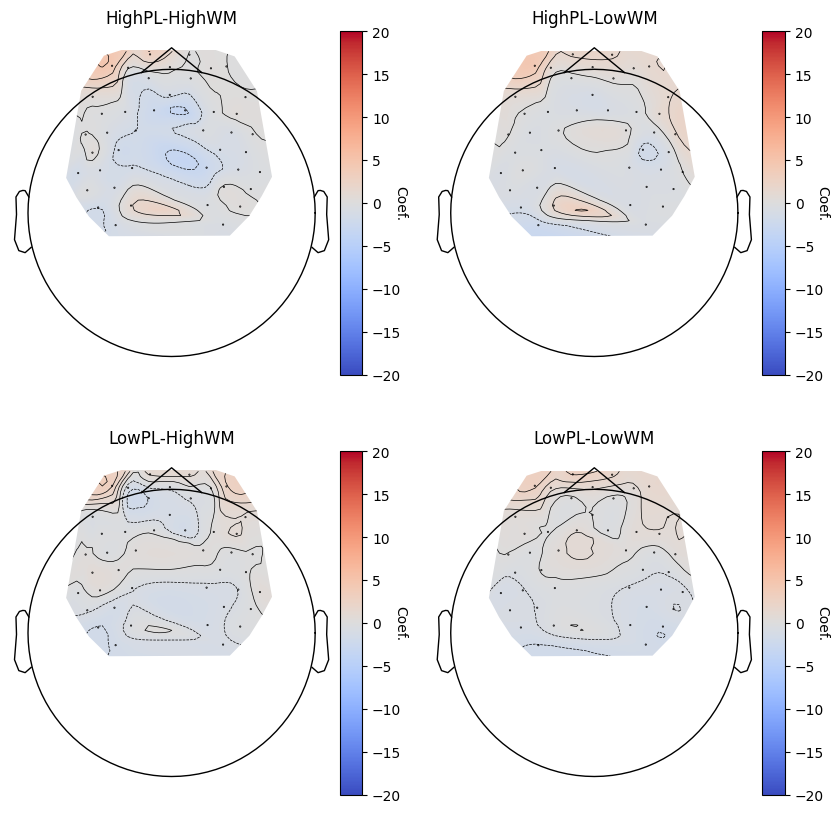

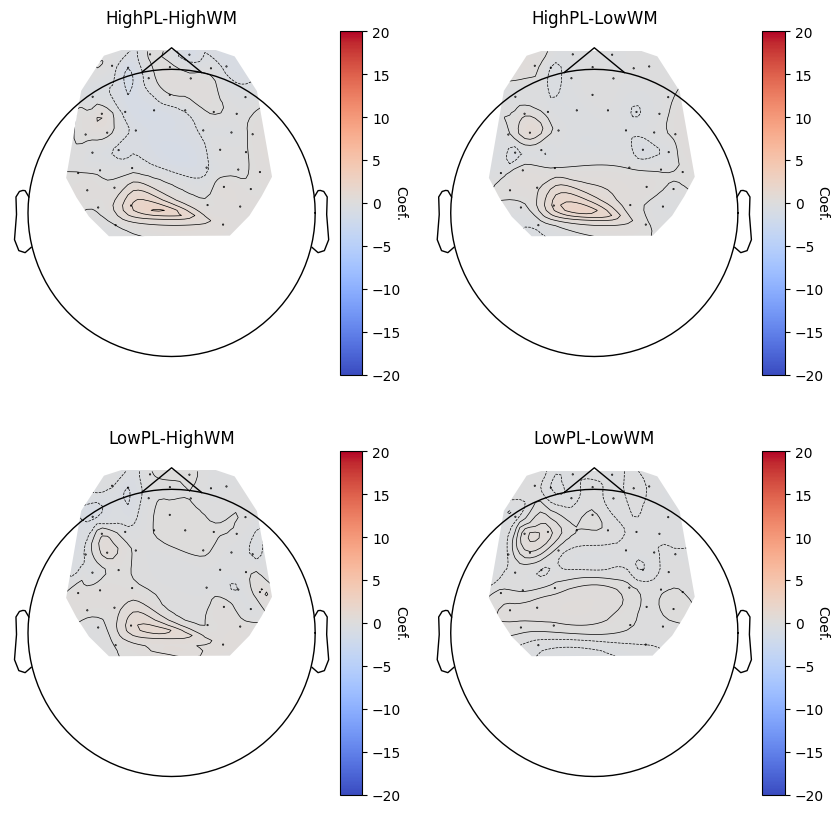

In [6]:
# Plot 2D 
conditions = ['HighPL-HighWM', 'HighPL-LowWM', 'LowPL-HighWM', 'LowPL-LowWM']
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(10, 10),
                        gridspec_kw=dict(width_ratios=[1, 1]))
grid_pairs = [[0,0], [0,1], [1,0], [1,1]]

idx = 0
for cond in conditions:
    cur_row = grid_pairs[idx][0]
    cur_col = grid_pairs[idx][1]
    mne_nirs.visualisation.plot_glm_group_topo(raw_haemo_long.copy().pick(picks="hbo"),
                        ch_model_df_hbo.query(f"Condition in ['{cond}']"),
                        colorbar=True, axes=axes[cur_row, cur_col],
                        vlim=(-20, 20), cmap=mpl.cm.coolwarm, threshold=False)
    idx += 1
plt.show()

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(10, 10),
                        gridspec_kw=dict(width_ratios=[1, 1]))
grid_pairs = [[0,0], [0,1], [1,0], [1,1]]
idx = 0
for cond in conditions:
    cur_row = grid_pairs[idx][0]
    cur_col = grid_pairs[idx][1]
    mne_nirs.visualisation.plot_glm_group_topo(raw_haemo_long.copy().pick(picks="hbr"),
                        ch_model_df_hbr.query(f"Condition in ['{cond}']"),
                        colorbar=True, axes=axes[cur_row, cur_col],
                        vlim=(-20, 20), cmap=mpl.cm.coolwarm, threshold=False)
    idx += 1
plt.show()

# Group level topoplot - only significant

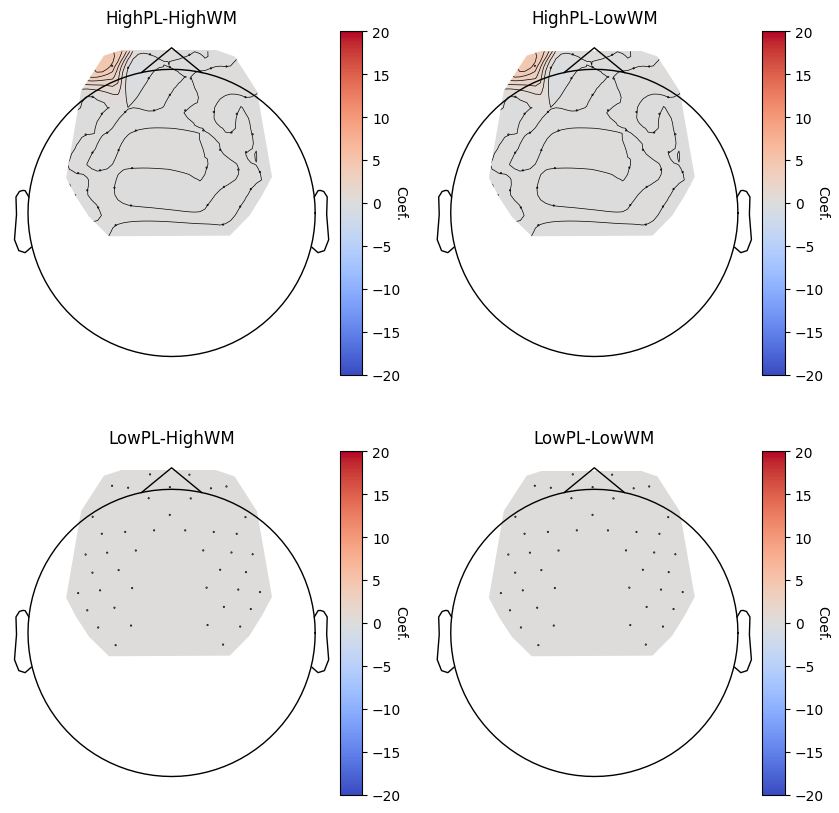

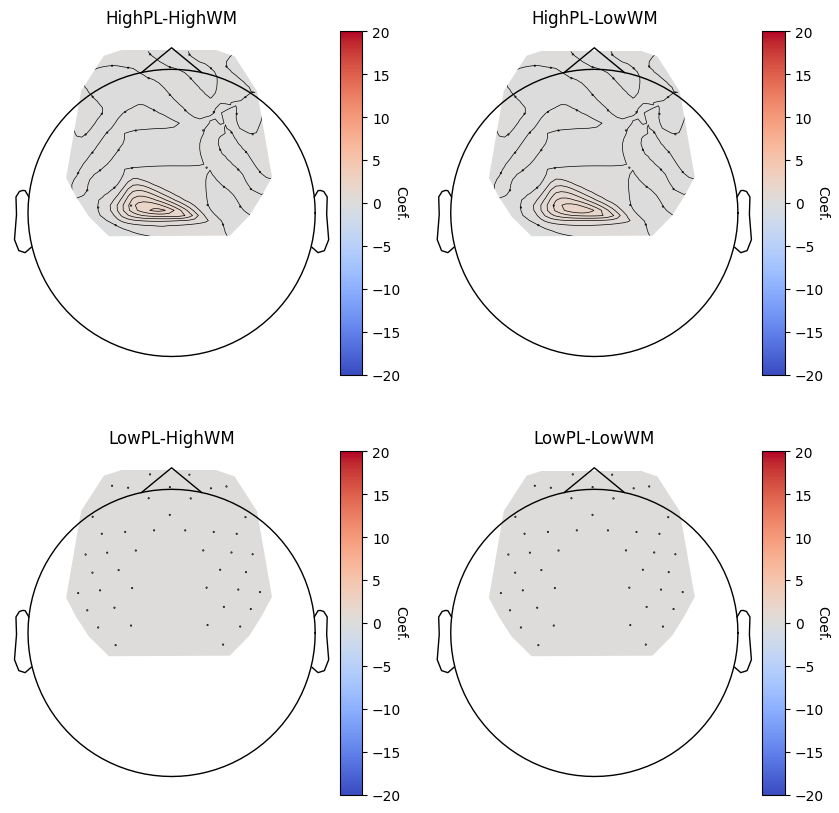

In [7]:
conditions = ['HighPL-HighWM', 'HighPL-LowWM', 'LowPL-HighWM', 'LowPL-LowWM']
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(10, 10),
                        gridspec_kw=dict(width_ratios=[1, 1]))
grid_pairs = [[0,0], [0,1], [1,0], [1,1]]
idx = 0
for cond in conditions:

    cur_row = grid_pairs[idx][0]
    cur_col = grid_pairs[idx][1]
    
    stats_cond = (
        ch_model_df_hbo
        .query(f"Condition == '{cond}'")
        .copy()
    )
    
    # Manually zero non‑significant estimates
    stats_cond.loc[~stats_cond["Significant"], "Coef."] = 0.0
    
    mne_nirs.visualisation.plot_glm_group_topo(
        raw_haemo_long.copy().pick(picks="hbo"),
        stats_cond,
        colorbar=True,
        axes=axes[cur_row, cur_col],
        vlim=(-20, 20),
        cmap=mpl.cm.coolwarm,
        threshold=False,
    )

    idx += 1
plt.show()

conditions = ['HighPL-HighWM', 'HighPL-LowWM', 'LowPL-HighWM', 'LowPL-LowWM']
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(10, 10),
                        gridspec_kw=dict(width_ratios=[1, 1]))
grid_pairs = [[0,0], [0,1], [1,0], [1,1]]
idx = 0
for cond in conditions:

    cur_row = grid_pairs[idx][0]
    cur_col = grid_pairs[idx][1]
    
    stats_cond = (
        ch_model_df_hbr
        .query(f"Condition == '{cond}'")
        .copy()
    )
    
    # Manually zero non‑significant estimates
    stats_cond.loc[~stats_cond["Significant"], "Coef."] = 0.0
    
    mne_nirs.visualisation.plot_glm_group_topo(
        raw_haemo_long.copy().pick(picks="hbr"),
        stats_cond,
        colorbar=True,
        axes=axes[cur_row, cur_col],
        vlim=(-20, 20),
        cmap=mpl.cm.coolwarm,
        threshold=False,
    )

    idx += 1
plt.show()


# Group level analysis - Contrasts

Opening raw data file data/raw.fif...
    Range : 0 ... 4897 =      0.000 ...   962.789 secs
Ready.
0 FDR-significant channel × contrast tests out of 264
(none)


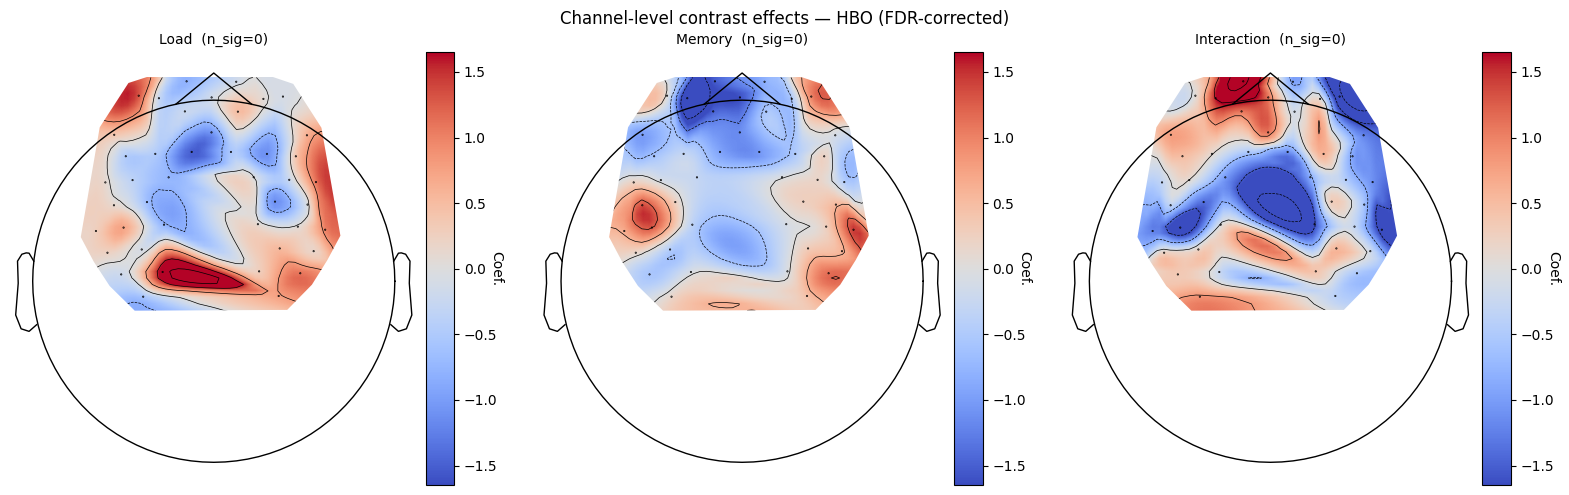

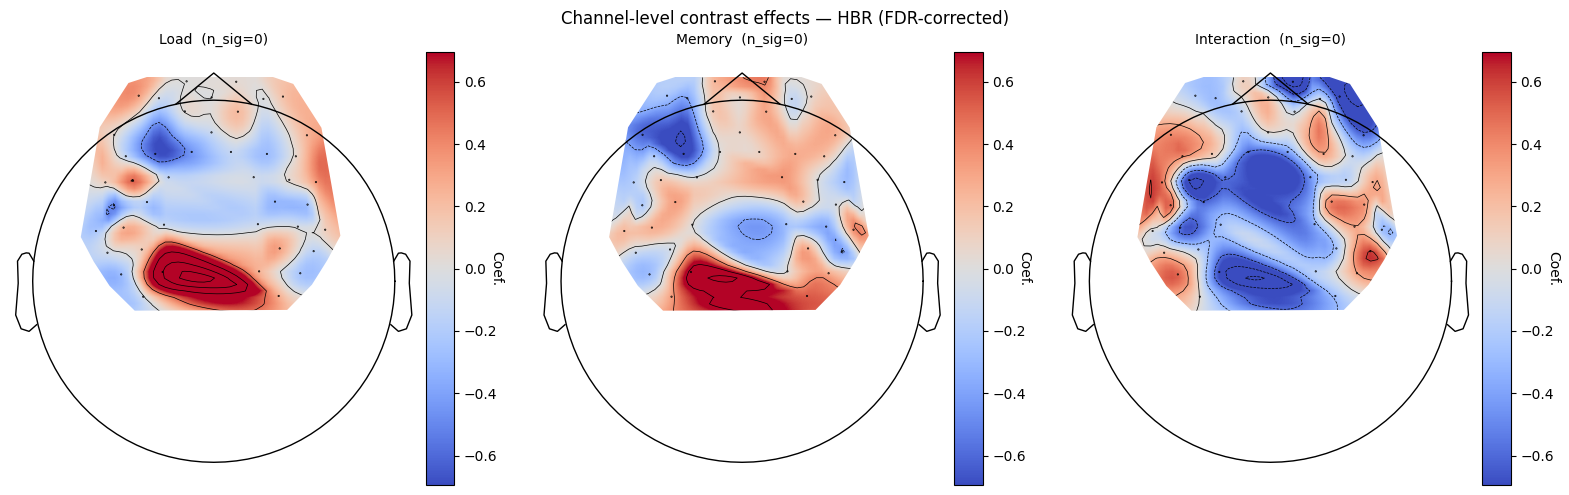

In [8]:
from statsmodels.stats.multitest import multipletests

_COND_LOAD   = {"HighPL-HighWM": "High", "HighPL-LowWM": "High",
                "LowPL-HighWM":  "Low",  "LowPL-LowWM":  "Low"}
_COND_MEMORY = {"HighPL-HighWM": "High", "HighPL-LowWM": "Low",
                "LowPL-HighWM":  "High", "LowPL-LowWM":  "Low"}
_TERMS = {
    "Load":        "Load[T.High]",
    "Memory":      "Memory[T.High]",
    "Interaction": "Load[T.High]:Memory[T.High]",
}
_CONDITIONS = ["HighPL-HighWM", "HighPL-LowWM", "LowPL-HighWM", "LowPL-LowWM"]

cha_data       = pd.read_csv("data/cha_data.csv", index_col=0)
raw_haemo_long = mne.io.read_raw_fif("data/raw.fif")

ch_contrast_records = []

for chroma in ["hbo", "hbr"]:
    ch_data = cha_data.query(
        "Condition in @_CONDITIONS and channel_ok == True and Chroma == @chroma"
    ).copy()
    ch_data["theta"] *= 1e6
    ch_data["Load"]   = ch_data["Condition"].map(_COND_LOAD)
    ch_data["Memory"] = ch_data["Condition"].map(_COND_MEMORY)
    ch_data["Load"]   = pd.Categorical(ch_data["Load"],   categories=["Low", "High"])
    ch_data["Memory"] = pd.Categorical(ch_data["Memory"], categories=["Low", "High"])

    ch_names = raw_haemo_long.copy().pick(chroma).ch_names

    for ch in ch_names:
        d = ch_data[ch_data["ch_name"] == ch]
        if d.empty:
            continue
        try:
            mdl = smf.mixedlm(
                "theta ~ Load * Memory", d, groups=d["subject"]
            ).fit(maxiter=2000, disp=False)
        except Exception:
            continue
        for label, term in _TERMS.items():
            if term in mdl.pvalues.index:
                ch_contrast_records.append({
                    "ch_name":   ch,
                    "Chroma":    chroma,
                    "Condition": label,
                    "Coef.":     mdl.params[term],
                    "Std.Err.":  mdl.bse[term],
                    "z":         mdl.tvalues[term],
                    "P>|z|":     mdl.pvalues[term],
                })

ch_contrast_df = pd.DataFrame(ch_contrast_records)

reject, pvals_fdr, _, _ = multipletests(ch_contrast_df["P>|z|"].values, alpha=0.05, method="fdr_bh")
ch_contrast_df["Significant"] = reject
ch_contrast_df["P_FDR"] = pvals_fdr

print(f"{reject.sum()} FDR-significant channel × contrast tests out of {len(reject)}")
if reject.any():
    print(ch_contrast_df[ch_contrast_df["Significant"]].to_string(index=False))
else:
    print("(none)")

for chroma in ["hbo", "hbr"]:
    raw_pick = raw_haemo_long.copy().pick(chroma)
    df_chroma = ch_contrast_df[ch_contrast_df["Chroma"] == chroma]

    # Symmetric colour limit at the 95th percentile of absolute coefficients
    vmax = np.percentile(df_chroma["Coef."].abs(), 95)

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    fig.suptitle(f"Channel-level contrast effects — {chroma.upper()} (FDR-corrected)", fontsize=12)

    for ax, term_label in zip(axes, ["Load", "Memory", "Interaction"]):
        stats_cond = df_chroma[df_chroma["Condition"] == term_label].copy()

        mne_nirs.visualisation.plot_glm_group_topo(
            raw_pick,
            stats_cond,
            colorbar=True,
            axes=ax,
            vlim=(-vmax, vmax),
            cmap=mpl.cm.coolwarm,
            threshold=False,
        )
        n_sig = stats_cond["Significant"].sum()
        ax.set_title(f"{term_label}  (n_sig={n_sig})", fontsize=10)

    plt.tight_layout()
    plt.show()

# 3D visualization

In [9]:
# https://mne.tools/mne-nirs/dev/generated/mne_nirs.visualisation.plot_nirs_source_detector.html
# One value should be specified per channel in the same order as info.chs.

# Fetch anatomical labels
mne.datasets.fetch_hcp_mmp_parcellation(subjects_dir=subjects_dir, accept=True)
labels_combined = mne.read_labels_from_annot('fsaverage', 'PALS_B12_Brodmann', 'both', subjects_dir=subjects_dir)

# Get correct order for channel values
hbo_idx = mne.pick_types(raw_haemo_long.info, fnirs="hbo")
info_hbo = mne.pick_info(raw_haemo_long.info, hbo_idx)

# Plot each condition
conditions = ['HighPL-HighWM', 'HighPL-LowWM', 'LowPL-HighWM', 'LowPL-LowWM']
#conditions = ['HighPL-HighWM']
for cond in conditions:

    print(f"\nVisualizing condition {cond}\n")
    
    stats_cond = (
        ch_model_df_hbo
        .query(f"Condition == '{cond}'")
        .copy()
    )

    # Order stats according to info channel order
    stats_cond["channel_clean"] = stats_cond["ch_name"].str.split(":").str[0]
    stats_cond = stats_cond.set_index("channel_clean")
    stats_cond = stats_cond.reindex(info_hbo["ch_names"])
    stats_cond_coeff = stats_cond["Coef."].values

    # Set up colors based on df values
    values = stats_cond_coeff.copy()
    vmax = np.nanmax(np.abs(values))
    norm = plt.Normalize(vmin=-vmax, vmax=vmax)
    cmap = plt.cm.RdBu_r

    # Zero out non-significant
    mask = stats_cond["Significant"].values
    values[~mask] = 0.0

    # Set up colors for montage
    colors = cmap(norm(values))

    # Set up colors for cortex projection
    clim = dict(kind="value", lims=[-vmax, 0, vmax])

    # Plot the projection
    brain = mne_nirs.visualisation.plot_glm_surface_projection(
        raw_haemo_long.copy().pick("hbo"), 
        stats_cond, 
        colorbar=True,
        #clim=clim,
    )

    # Add montage
    brain.add_sensors(
        info_hbo,
        trans="fsaverage",
        fnirs=["channels", "pairs"],
        sensor_colors = colors,
    )


    # Dorsolateral prefrontal
    vis_label = [label for label in labels_combined if label.name == 'Brodmann.9-lh'][0]
    brain.add_label(vis_label, borders=True, color='purple')
    vis_label = [label for label in labels_combined if label.name == 'Brodmann.9-rh'][0]
    brain.add_label(vis_label, borders=True, color='purple')
    vis_label = [label for label in labels_combined if label.name == 'Brodmann.46-lh'][0]
    brain.add_label(vis_label, borders=True, color='purple')
    vis_label = [label for label in labels_combined if label.name == 'Brodmann.46-rh'][0]
    brain.add_label(vis_label, borders=True, color='purple')

    # Frontopolar
    vis_label = [label for label in labels_combined if label.name == 'Brodmann.10-lh'][0]
    brain.add_label(vis_label, borders=True, color='red')
    vis_label = [label for label in labels_combined if label.name == 'Brodmann.10-rh'][0]
    brain.add_label(vis_label, borders=True, color='red')

    # FEF
    vis_label = [label for label in labels_combined if label.name == 'Brodmann.8-lh'][0]
    brain.add_label(vis_label, borders=True, color='cyan')
    vis_label = [label for label in labels_combined if label.name == 'Brodmann.8-rh'][0]
    brain.add_label(vis_label, borders=True, color='cyan')

    # IFG
    vis_label = [label for label in labels_combined if label.name == 'Brodmann.44-lh'][0]
    brain.add_label(vis_label, borders=True, color='green')
    vis_label = [label for label in labels_combined if label.name == 'Brodmann.44-rh'][0]
    brain.add_label(vis_label, borders=True, color='green')

    # Premotor and SMA
    vis_label = [label for label in labels_combined if label.name == 'Brodmann.6-lh'][0]
    brain.add_label(vis_label, borders=True, color='blue')
    vis_label = [label for label in labels_combined if label.name == 'Brodmann.6-rh'][0]
    brain.add_label(vis_label, borders=True, color='blue')

    print(stats_cond[stats_cond["Significant"] == True][["ch_name", "Coef.", "Significant", "P>|z|"]])


Reading labels from parcellation...
   read 82 labels from /Users/alexander.kvist/mne_data/MNE-sample-data/subjects/fsaverage/label/lh.PALS_B12_Brodmann.annot
   read 46 labels from /Users/alexander.kvist/mne_data/MNE-sample-data/subjects/fsaverage/label/rh.PALS_B12_Brodmann.annot

Visualizing condition HighPL-HighWM



ERROR:asyncio:Exception in callback <_asyncio.TaskStepMethWrapper object at 0x11c192650>()
handle: <Handle <_asyncio.TaskStepMethWrapper object at 0x11c192650>()>
Traceback (most recent call last):
  File "/opt/homebrew/Cellar/python@3.14/3.14.2/Frameworks/Python.framework/Versions/3.14/lib/python3.14/asyncio/events.py", line 94, in _run
    self._context.run(self._callback, *self._args)
    ~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
RuntimeError: cannot enter context: <_contextvars.Context object at 0x10ad51a40> is already entered


Channel types::	hbo: 44
                 ch_name     Coef.  Significant     P>|z|
channel_clean                                            
S2_D3 hbo      S2_D3 hbo  3.845548         True  0.000066

Visualizing condition HighPL-LowWM



Channel types::	hbo: 44


ERROR:asyncio:Task was destroyed but it is pending!
task: <Task pending name='Task-65' coro=<_async_in_context.<locals>.run_in_context() running at /Users/alexander.kvist/project_local/Perceptual-fnirs/venv/lib/python3.14/site-packages/ipykernel/utils.py:60> wait_for=<Task pending name='Task-92' coro=<Kernel.shell_main() running at /Users/alexander.kvist/project_local/Perceptual-fnirs/venv/lib/python3.14/site-packages/ipykernel/kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at /Users/alexander.kvist/project_local/Perceptual-fnirs/venv/lib/python3.14/site-packages/zmq/eventloop/zmqstream.py:563]>
ERROR:asyncio:Task was destroyed but it is pending!
task: <Task pending name='Task-92' coro=<Kernel.shell_main() running at /Users/alexander.kvist/project_local/Perceptual-fnirs/venv/lib/python3.14/site-packages/ipykernel/kernelbase.py:597> cb=[Task.task_wakeup()]>
/Users/alexander.kvist/project_local/Perceptual-fnirs/venv/lib/python3.14/site-packa

                 ch_name     Coef.  Significant     P>|z|
channel_clean                                            
S2_D3 hbo      S2_D3 hbo  3.780261         True  0.000088

Visualizing condition LowPL-HighWM



Channel types::	hbo: 44
Empty DataFrame
Columns: [ch_name, Coef., Significant, P>|z|]
Index: []

Visualizing condition LowPL-LowWM



Channel types::	hbo: 44
Empty DataFrame
Columns: [ch_name, Coef., Significant, P>|z|]
Index: []
